# FlowLens: IT Incident KPI Analysis

This notebook analyzes the processed IT Incident logs to extract key business metrics such as **Mean Time to Resolution (MTTR)**, **SLA Breach Rates**, and the **Ping-Pong Effect** (reassignments).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure style
sns.set_theme(style="whitegrid")

# Load processed data
df_log = pd.read_csv('../data/processed/Cleaned_EventLog.csv')
df_kpis = pd.read_csv('../data/processed/Ticket_KPIs.csv')

df_kpis.head()

,TicketNum,min,max,Resolution_Hours,Ping_Pong_Count
0,5078917.0,2010-07-01 00:00:00,2010-07-06 18:00:00,138.000000,2.0
1,5078921.0,2010-07-01 00:01:00,2010-07-01 00:25:00,0.400000,0.0
2,5078922.0,2010-07-01 00:01:00,2010-07-01 09:42:00,9.683333,0.0
3,5078971.0,2010-07-01 01:09:00,2010-07-14 14:41:00,325.533333,0.0
4,5078978.0,2010-07-01 01:19:00,2010-07-14 14:43:00,325.400000,0.0


## 1. Resolution Time (MTTR) Analysis
Let's visualize how long tickets take to resolve and identify the median vs 90th percentile resolution time.

Median Time to Resolution: 22.85 hours
Mean Time to Resolution: 153.61 hours
90th Percentile Resolution: 355.81 hours


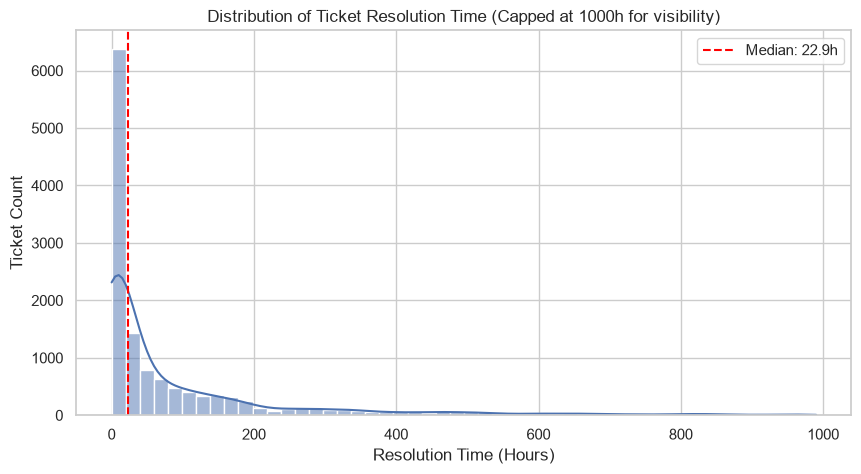

In [2]:
# Calculate MTTR metrics
mttr_median = df_kpis['Resolution_Hours'].median()
mttr_mean = df_kpis['Resolution_Hours'].mean()
mttr_p90 = df_kpis['Resolution_Hours'].quantile(0.90)

print(f"Median Time to Resolution: {mttr_median:.2f} hours")
print(f"Mean Time to Resolution: {mttr_mean:.2f} hours")
print(f"90th Percentile Resolution: {mttr_p90:.2f} hours")

plt.figure(figsize=(10, 5))
sns.histplot(df_kpis[df_kpis['Resolution_Hours'] < 1000]['Resolution_Hours'], bins=50, kde=True)
plt.axvline(mttr_median, color='red', linestyle='--', label=f'Median: {mttr_median:.1f}h')
plt.title('Distribution of Ticket Resolution Time (Capped at 1000h for visibility)')
plt.xlabel('Resolution Time (Hours)')
plt.ylabel('Ticket Count')
plt.legend()
plt.show()

## 2. SLA Breach Analysis
Assuming a standard SLA of **72 hours**, how many tickets breached the SLA?

In [3]:
SLA_LIMIT_HOURS = 72

df_kpis['SLA_Breached'] = df_kpis['Resolution_Hours'] > SLA_LIMIT_HOURS
breach_rate = df_kpis['SLA_Breached'].mean() * 100

print(f"Overall SLA Breach Rate (>{SLA_LIMIT_HOURS} hours): {breach_rate:.2f}%")

Overall SLA Breach Rate (>72 hours): 33.54%


## 3. The Ping-Pong Effect (Reassignments)
Tickets that bounce back and forth between support groups waste time. We measure the volume of tickets that underwent multiple reassignments.

Percentage of tickets by Reassignment Count:
Ping_Pong_Count
0.0    84.487208
2.0     9.400575
4.0     2.433090
1.0     1.135442
6.0     0.825776
Name: proportion, dtype: float64


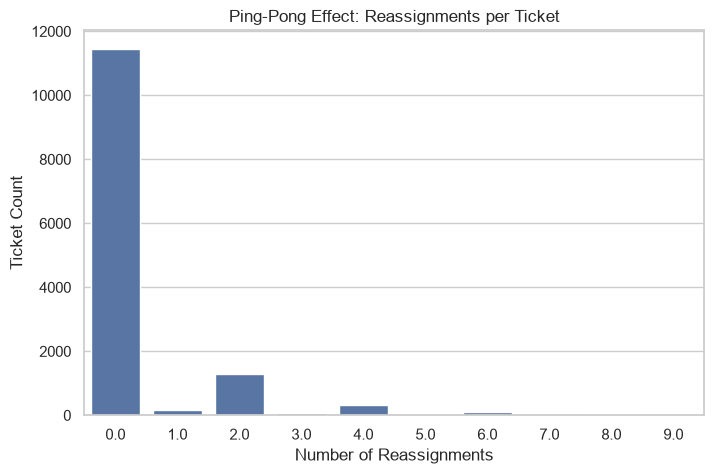

In [4]:
ping_pong_dist = df_kpis['Ping_Pong_Count'].value_counts(normalize=True) * 100

print("Percentage of tickets by Reassignment Count:")
print(ping_pong_dist.head(5))

plt.figure(figsize=(8, 5))
sns.countplot(data=df_kpis[df_kpis['Ping_Pong_Count'] < 10], x='Ping_Pong_Count')
plt.title('Ping-Pong Effect: Reassignments per Ticket')
plt.xlabel('Number of Reassignments')
plt.ylabel('Ticket Count')
plt.show()